# TP2 — Analyse des architectures Flower
**Binôme : Nom1 – Nom2** · Module Apprentissage Collaboratif Distribué · Master 2

Question directrice : *comment le choix de l'architecture et du mode d'orchestration influence-t-il la convergence, la latence et le comportement d'un système d'apprentissage fédéré ?*

Ce notebook lit les CSV de `logs/`, produit les 10 visualisations demandées (dossier `figures/`), remplit les tableaux de l'énoncé et rédige l'analyse. **Tous les tableaux et figures sont recalculés à partir des CSV** : en cas de nouvelle exécution des expériences, relancer le notebook (*Kernel → Restart & Run All*) ; seuls les commentaires rédigés (section 6) sont à relire.

## Partie A — Repérage du code : rôles du client, du serveur, de l'Edge et du Cloud

| Élément | Où le trouver | Ce qu'il fait |
|---|---|---|
| `get_parameters()` | `classical/client.py`, l. 49 | Appelle `get_parameters(self.model)` (`common/model.py`) : renvoie les poids du modèle local sous forme de **liste de tableaux NumPy** (poids et biais de la couche 784→10), le format que Flower sait transmettre. Flower ne l'utilise que si le serveur n'a pas de paramètres initiaux ; ici le serveur en fournit (`initial_parameters`). |
| `fit()` | `classical/client.py`, l. 52 | **C'est ici que a lieu l'entraînement local.** (1) `set_parameters` charge le modèle global reçu ; (2) pause artificielle `time.sleep(delay)` ; (3) `train_local(...)` (`common/model.py`, l. 47) entraîne sur les données locales (`trainloader`, 1 époque) ; (4) renvoie les **nouveaux poids**, le **nombre d'exemples** (`len(trainloader.dataset)`) et des métriques (`train_loss`, `client_id`, `delay_s`). |
| `evaluate()` | `classical/client.py`, l. 75 | Charge le modèle reçu puis l'évalue sur `testloader`, la **partition locale du jeu de test MNIST** du client (≈ 1/3 des 10 000 images). Métriques : **loss** (entropie croisée) et **accuracy**. *Dans nos serveurs (`fraction_evaluate=0.0`), Flower n'appelle pas cette méthode* : les valeurs des CSV viennent de `evaluate_fn` côté serveur, sur les 10 000 images du test global. |
| Données locales | `client.py`, l. 39 (`__init__`) → `common/data.py`, l. 32 | `load_client_data(partition_id, num_partitions, ...)` charge MNIST et ne garde que la **partition du client** (20 000 exemples d'entraînement pour 3 clients) ; `--max-train-samples` limite ce nombre. |
| **FedAvg** | `classical/server_sync.py`, l. 45 | Classe `TimedFedAvg(fl.server.strategy.FedAvg)`. Son `aggregate_fit` appelle `super().aggregate_fit(...)`, c'est-à-dire le FedAvg de Flower : moyenne des poids des clients **pondérée par leur nombre d'exemples**. L'agrégation se fait **au niveau du serveur, jamais chez le client** ; `TimedFedAvg` ajoute seulement le chronométrage des rounds. |
| Serveur Flower | `classical/server_sync.py` | Distribue le modèle global, attend les clients (`min_fit_clients = min_available_clients`), reçoit les mises à jour, agrège (FedAvg), évalue le modèle global (`evaluate_fn`, l. 81) et écrit le CSV. |
| Serveur Edge | `hierarchical/edge_server.py` | Même logique que le serveur Flower classique, limitée à **son groupe de 3 clients** ; sauvegarde à chaque round les paramètres agrégés dans `params/` (`.npz`, `_keys.json`, `_meta.json`). |
| Cloud | `hierarchical/cloud_server.py` | Lit les fichiers des Edge et calcule la moyenne (uniforme ou pondérée par Nₑ). **Il n'entraîne rien** ; il évalue seulement le modèle global sur le test MNIST. |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('..') if Path.cwd().name == 'analysis' else Path('.')
LOGS = ROOT / 'logs'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
COL = {'S1': '#4C78A8', 'S2': '#F58518', 'A1': '#54A24B', 'A2': '#E45756',
       'E0': '#B279A2', 'E1': '#72B7B2', 'Cloud': '#9D755D'}

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=150)
    plt.show()

print('Dossier logs :', LOGS.resolve())

Dossier logs : /home/claude/work/logs


## 0. Chargement des données

In [2]:
def read_if_exists(name):
    p = LOGS / name
    if not p.exists():
        print(f'Absent : {p}')
        return None
    df = pd.read_csv(p)
    print(f'{name}: {len(df)} lignes')
    return df

sync_h  = read_if_exists('sync_homogeneous.csv')
sync_s  = read_if_exists('sync_straggler.csv')
async_h = read_if_exists('async_homogeneous.csv')
async_s = read_if_exists('async_straggler.csv')
edge0   = read_if_exists('edge_0.csv')
edge1   = read_if_exists('edge_1.csv')
cloud   = read_if_exists('cloud_results.csv')

# Le CSV Cloud contient deux configurations : on les distingue par le nombre total d'exemples.
cloud['scenario'] = np.where(cloud['total_examples'] == cloud['total_examples'].max(),
                             'Équilibré', 'Déséquilibré')
display(cloud)

sync_homogeneous.csv: 5 lignes
sync_straggler.csv: 5 lignes
async_homogeneous.csv: 15 lignes
async_straggler.csv: 15 lignes
edge_0.csv: 5 lignes
edge_1.csv: 5 lignes
cloud_results.csv: 4 lignes


,edge_round,weighting,loss,accuracy,num_edges,total_examples,timestamp,scenario
0,5,uniform,0.311862,0.9150,2,60000,2026-10-23T20:10:16+00:00,Équilibré
1,5,examples,0.311862,0.9150,2,60000,2026-10-23T20:10:28+00:00,Équilibré
2,5,uniform,0.399205,0.8944,2,16500,2026-10-23T20:41:30+00:00,Déséquilibré
3,5,examples,0.380192,0.8984,2,16500,2026-10-23T20:41:36+00:00,Déséquilibré


**Deux précautions de lecture sur les données**

1. **Round 1 des Edge.** Dans `edge_0.csv` / `edge_1.csv`, la durée du round 1 vaut environ 470 s. Ce n'est pas du calcul : le chronomètre démarre dès `configure_fit`, avant que les clients ne soient tous connectés (Flower attend les `min_available_clients`). Cette durée contient donc le **temps de connexion des clients** et est exclue des moyennes (rounds 2 à 5 seulement).
2. **Quelle exécution Edge ?** Les durées d'Edge 0 (≈ 5 s) et d'Edge 1 (≈ 2,4 s) correspondent à l'exécution avec **client lent C2 = 3 s dans Edge 0** (partie J). Les modèles obtenus sont les mêmes qu'en configuration équilibrée sans retard (graines fixes) : seule la durée change.

In [3]:
print('Durée du round 1 (artefact de connexion) : Edge 0 =', round(edge0.loc[0, 'round_duration_s'], 1), 's ;',
      'Edge 1 =', round(edge1.loc[0, 'round_duration_s'], 1), 's')
clean = lambda df: df[df['round'] >= 2]

Durée du round 1 (artefact de connexion) : Edge 0 = 473.5 s ; Edge 1 = 471.5 s


## 1. Architecture synchrone : accuracy, loss et durée des rounds (Fig. 1 à 3)

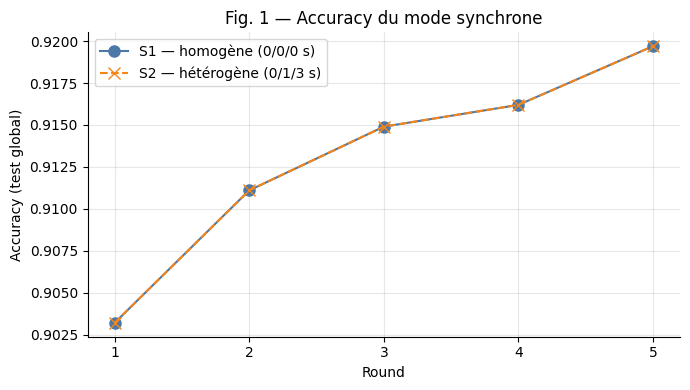

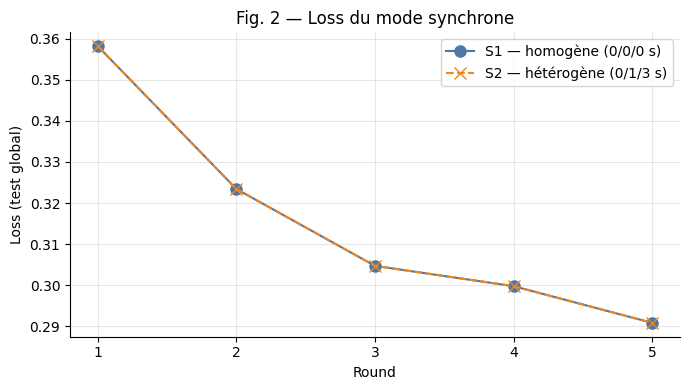

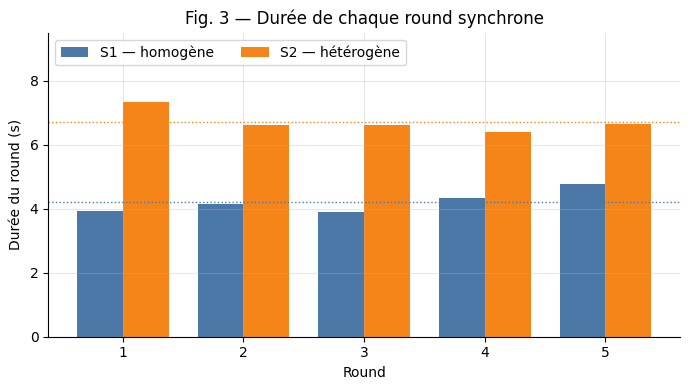

In [4]:
styles = [('S1 — homogène (0/0/0 s)', sync_h, COL['S1'], 'o', '-'),
          ('S2 — hétérogène (0/1/3 s)', sync_s, COL['S2'], 'x', '--')]

fig, ax = plt.subplots(figsize=(7, 4))
for lab, df, c, mk, ls in styles:
    ax.plot(df['round'], df['accuracy'], marker=mk, ls=ls, color=c, label=lab, ms=8)
ax.set(xlabel='Round', ylabel='Accuracy (test global)', title='Fig. 1 — Accuracy du mode synchrone')
ax.set_xticks(sync_h['round']); ax.legend()
save('fig01_sync_accuracy')

fig, ax = plt.subplots(figsize=(7, 4))
for lab, df, c, mk, ls in styles:
    ax.plot(df['round'], df['loss'], marker=mk, ls=ls, color=c, label=lab, ms=8)
ax.set(xlabel='Round', ylabel='Loss (test global)', title='Fig. 2 — Loss du mode synchrone')
ax.set_xticks(sync_h['round']); ax.legend()
save('fig02_sync_loss')

fig, ax = plt.subplots(figsize=(7, 4))
w = .38
ax.bar(sync_h['round'] - w/2, sync_h['round_duration_s'], w, color=COL['S1'], label='S1 — homogène')
ax.bar(sync_s['round'] + w/2, sync_s['round_duration_s'], w, color=COL['S2'], label='S2 — hétérogène')
ax.axhline(sync_h['round_duration_s'].mean(), color=COL['S1'], ls=':', lw=1)
ax.axhline(sync_s['round_duration_s'].mean(), color=COL['S2'], ls=':', lw=1)
ax.set(xlabel='Round', ylabel='Durée du round (s)', title='Fig. 3 — Durée de chaque round synchrone')
ax.set_xticks(sync_h['round']); ax.set_ylim(0, 9.5); ax.legend(loc='upper left', ncol=2)
save('fig03_sync_duree')

### Tableau 9.2 — Expérience S0 (référence) et Tableau 10.1 — S1 vs S2

In [5]:
t92 = sync_h[['round', 'accuracy', 'loss', 'round_duration_s']].rename(
    columns={'round': 'Round', 'accuracy': 'Accuracy', 'loss': 'Loss', 'round_duration_s': 'Durée (s)'})
display(t92.round({'Accuracy': 4, 'Loss': 4, 'Durée (s)': 2}).set_index('Round'))

def sync_summary(df):
    return {'Accuracy finale': df['accuracy'].iloc[-1], 'Loss finale': df['loss'].iloc[-1],
            'Temps total (s)': df['round_duration_s'].sum(),
            "Durée moyenne d'un round (s)": df['round_duration_s'].mean()}

t101 = pd.DataFrame({'S1 homogène': sync_summary(sync_h), 'S2 hétérogène': sync_summary(sync_s)})
display(t101.round(4))

ROW = "Durée moyenne d'un round (s)"
d_round = t101.loc[ROW, 'S2 hétérogène'] - t101.loc[ROW, 'S1 homogène']
print(f"Surcoût moyen par round dû au client lent : +{d_round:.2f} s (+{100 * d_round / t101.loc[ROW, 'S1 homogène']:.1f} %) ; "
      f"temps total : +{t101.loc['Temps total (s)', 'S2 hétérogène'] - t101.loc['Temps total (s)', 'S1 homogène']:.1f} s")

,Accuracy,Loss,Durée (s)
Round,,,
1,0.9032,0.3582,3.93
2,0.9111,0.3234,4.13
3,0.9149,0.3047,3.90
4,0.9162,0.2998,4.33
5,0.9197,0.2909,4.77


,S1 homogène,S2 hétérogène
Accuracy finale,0.9197,0.9197
Loss finale,0.2909,0.2909
Temps total (s),21.0665,33.5971
Durée moyenne d'un round (s),4.2133,6.7194


Surcoût moyen par round dû au client lent : +2.51 s (+59.5 %) ; temps total : +12.5 s


**Lecture.** Avec des délais 0 / 1 / 3 s, `T_round ≈ max(T₁, T₂, T₃)` : le round est cadencé par le client à 3 s (3 s de pause + son calcul), les deux autres attendent. Le round suivant ne commence qu'une fois les trois mises à jour reçues et agrégées. En revanche, l'accuracy et la loss finales sont **identiques** entre S1 et S2 (les courbes des Fig. 1–2 se superposent) : le retard modifie la latence, pas le calcul. L'accuracy seule ne suffit donc pas à caractériser un système fédéré : il faut la lire avec la durée.

## 2. Mode asynchrone : accuracy, loss, temps cumulé, contributions et staleness

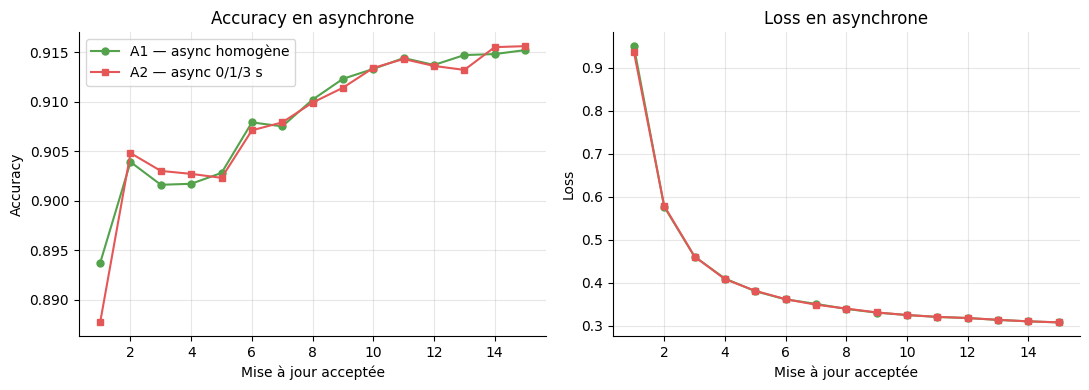

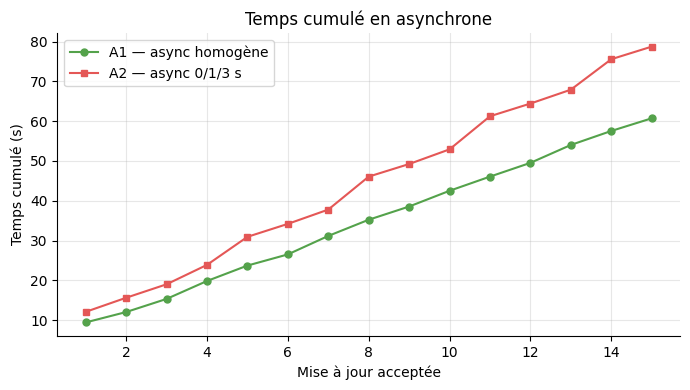

In [6]:
asy = [('A1 — async homogène', async_h, COL['A1'], 'o'),
       ('A2 — async 0/1/3 s', async_s, COL['A2'], 's')]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for lab, df, c, mk in asy:
    axes[0].plot(df['update'], df['accuracy'], marker=mk, color=c, label=lab, ms=5)
    axes[1].plot(df['update'], df['loss'], marker=mk, color=c, label=lab, ms=5)
axes[0].set(xlabel='Mise à jour acceptée', ylabel='Accuracy', title='Accuracy en asynchrone')
axes[1].set(xlabel='Mise à jour acceptée', ylabel='Loss', title='Loss en asynchrone')
axes[0].legend()
save('extra_async_acc_loss')

fig, ax = plt.subplots(figsize=(7, 4))
for lab, df, c, mk in asy:
    ax.plot(df['update'], df['elapsed_s'], marker=mk, color=c, label=lab, ms=5)
ax.set(xlabel='Mise à jour acceptée', ylabel='Temps cumulé (s)', title='Temps cumulé en asynchrone')
ax.legend()
save('extra_async_temps_cumule')

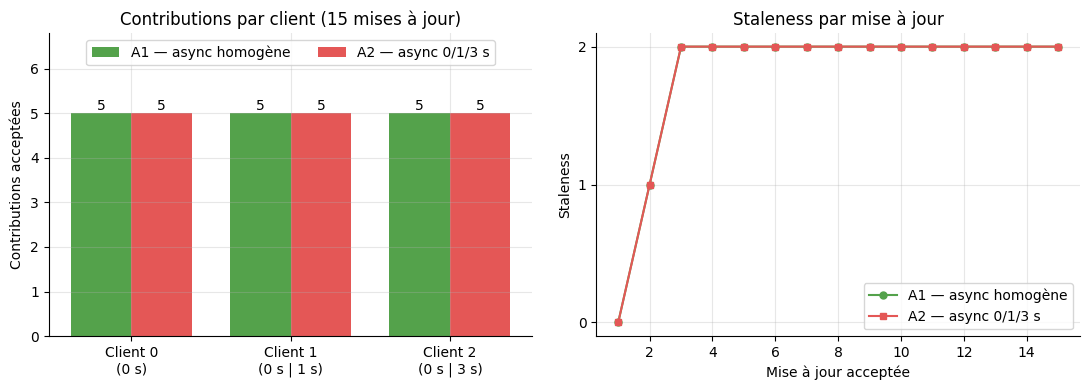

In [7]:
clients = [0, 1, 2]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# contributions par client
w = .38
for k, (lab, df, c, mk) in enumerate(asy):
    cnt = df.groupby('client').size().reindex(clients, fill_value=0)
    bars = axes[0].bar(np.array(clients) + (k - .5) * w, cnt.values, w, color=c, label=lab)
    axes[0].bar_label(bars)
axes[0].set_xticks(clients)
axes[0].set_xticklabels(['Client 0\n(0 s)', 'Client 1\n(0 s | 1 s)', 'Client 2\n(0 s | 3 s)'])
axes[0].set(ylabel='Contributions acceptées', title='Contributions par client (15 mises à jour)')
axes[0].set_ylim(0, 6.8); axes[0].legend(loc='upper center', ncol=2)

# staleness
for lab, df, c, mk in asy:
    axes[1].plot(df['update'], df['staleness'], marker=mk, color=c, label=lab, ms=5)
axes[1].set(xlabel='Mise à jour acceptée', ylabel='Staleness', title='Staleness par mise à jour')
axes[1].set_yticks([0, 1, 2]); axes[1].legend()
save('extra_async_contrib_staleness')

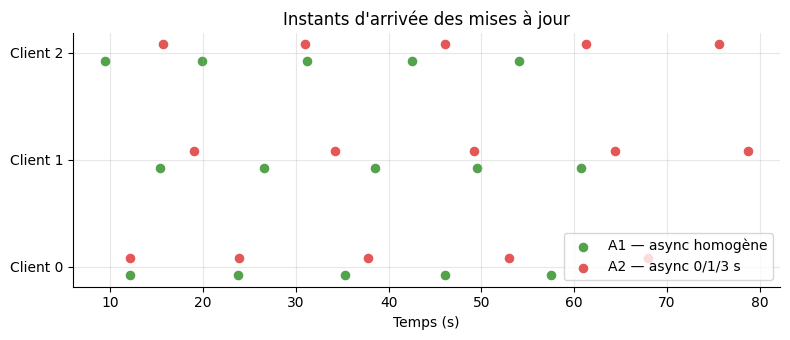

A1 — async homogène | ordre des clients : [2, 0, 1, 2, 0, 1, 2, 0, 1, 2, 0, 1, 2, 0, 1]
   écart moyen entre arrivées : 3.66 s | min/max : 2.61 / 4.64
   durée moyenne d'un cycle par client : {0: 11.5, 1: 12.1, 2: 10.8}
   staleness (valeurs) : {0: 1, 1: 1, 2: 13}
A2 — async 0/1/3 s | ordre des clients : [0, 2, 1, 0, 2, 1, 0, 2, 1, 0, 2, 1, 0, 2, 1]
   écart moyen entre arrivées : 4.76 s | min/max : 3.16 / 8.31
   durée moyenne d'un cycle par client : {0: 13.6, 1: 15.7, 2: 15.1}
   staleness (valeurs) : {0: 1, 1: 1, 2: 13}


In [8]:
# Ordre d'arrivée des mises à jour : un tourniquet strict révèle un client « à tour de rôle »
fig, ax = plt.subplots(figsize=(8, 3.5))
for lab, df, c, mk in asy:
    ax.scatter(df['elapsed_s'], df['client'] + (0.08 if lab.startswith('A2') else -0.08),
               color=c, label=lab, s=35)
ax.set_yticks(clients); ax.set_yticklabels(['Client 0', 'Client 1', 'Client 2'])
ax.set(xlabel='Temps (s)', title="Instants d'arrivée des mises à jour")
ax.legend()
save('extra_async_arrivees')

for lab, df, c, mk in asy:
    print(lab, '| ordre des clients :', df['client'].tolist())
    print('   écart moyen entre arrivées :', round(df['elapsed_s'].diff().mean(), 2), 's',
          '| min/max :', round(df['elapsed_s'].diff().min(), 2), '/', round(df['elapsed_s'].diff().max(), 2))
    print('   durée moyenne d\'un cycle par client :', df.groupby('client')['update_duration_s'].mean().round(1).to_dict())
    print('   staleness (valeurs) :', df['staleness'].value_counts().sort_index().to_dict())

### Stabilité : sync vs async

In [9]:
def stability(df):
    d = df['accuracy'].diff().dropna()
    return {"Baisses d'accuracy": f"{int((d < 0).sum())} / {len(d)}",
            'Écart-type de Δaccuracy': d.std(),
            'Plus forte baisse (pt)': 100 * d.min() if (d < 0).any() else 0.0,
            'Hausses de loss': f"{int((df['loss'].diff() > 0).sum())} / {len(d)}"}

t_stab = pd.DataFrame({'S1': stability(sync_h), 'S2': stability(sync_s),
                       'A1': stability(async_h), 'A2': stability(async_s)})
display(t_stab)

,S1,S2,A1,A2
Baisses d'accuracy,0 / 4,0 / 4,3 / 14,5 / 14
Écart-type de Δaccuracy,0.002752,0.002752,0.003029,0.004649
Plus forte baisse (pt),0.0,0.0,-0.23,-0.18
Hausses de loss,0 / 4,0 / 4,0 / 14,0 / 14


## 3. Synchrone vs asynchrone, à budget comparable (Fig. 4 à 6)

5 rounds × 3 clients (synchrone) = 15 contributions locales, comparées à 15 mises à jour acceptées en asynchrone.

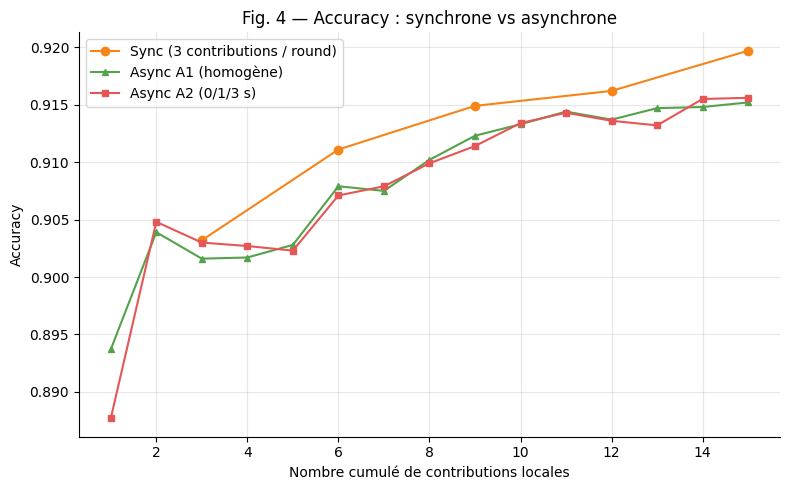

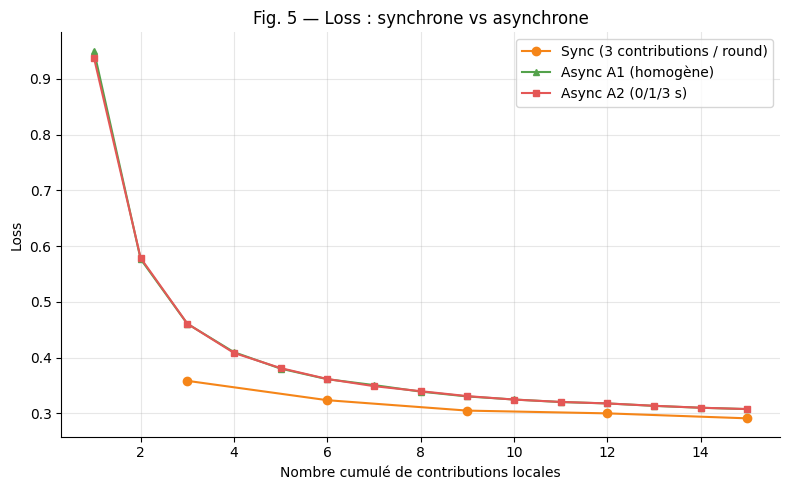

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sync_s['round'] * 3, sync_s['accuracy'], marker='o', color=COL['S2'], label='Sync (3 contributions / round)')
ax.plot(async_h['update'], async_h['accuracy'], marker='^', ms=4, color=COL['A1'], label='Async A1 (homogène)')
ax.plot(async_s['update'], async_s['accuracy'], marker='s', ms=4, color=COL['A2'], label='Async A2 (0/1/3 s)')
ax.set(xlabel='Nombre cumulé de contributions locales', ylabel='Accuracy',
       title='Fig. 4 — Accuracy : synchrone vs asynchrone'); ax.legend()
save('fig04_accuracy_sync_vs_async')

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sync_s['round'] * 3, sync_s['loss'], marker='o', color=COL['S2'], label='Sync (3 contributions / round)')
ax.plot(async_h['update'], async_h['loss'], marker='^', ms=4, color=COL['A1'], label='Async A1 (homogène)')
ax.plot(async_s['update'], async_s['loss'], marker='s', ms=4, color=COL['A2'], label='Async A2 (0/1/3 s)')
ax.set(xlabel='Nombre cumulé de contributions locales', ylabel='Loss',
       title='Fig. 5 — Loss : synchrone vs asynchrone'); ax.legend()
save('fig05_loss_sync_vs_async')

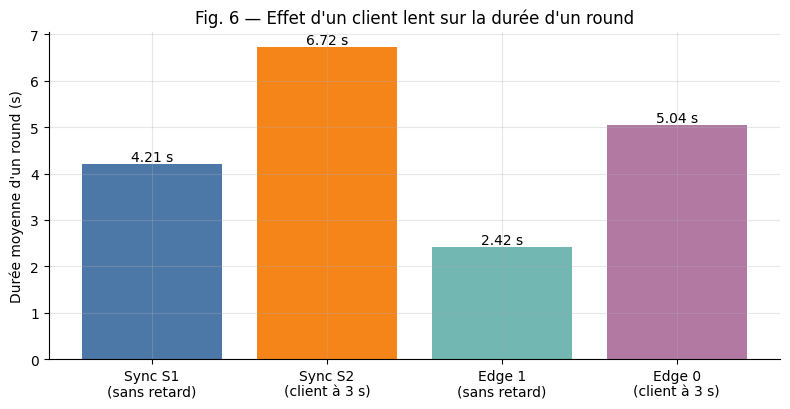

Sync : +59.5 % de temps total avec le client lent (21.1 → 33.6 s)
Async : +29.6 % de temps total avec le client lent (60.7 → 78.7 s)
Async / Sync : x2.9 (homogène), x2.3 (avec client lent)
Edge 0 / Edge 1 : x2.08 (rounds 2 à 5)


In [11]:
# Fig. 6 — effet d'un client lent, toutes architectures confondues (durée moyenne d'un round)
e0_mean, e1_mean = clean(edge0)['round_duration_s'].mean(), clean(edge1)['round_duration_s'].mean()
labels = ['Sync S1\n(sans retard)', 'Sync S2\n(client à 3 s)', 'Edge 1\n(sans retard)', 'Edge 0\n(client à 3 s)']
vals = [sync_h['round_duration_s'].mean(), sync_s['round_duration_s'].mean(), e1_mean, e0_mean]
colors = [COL['S1'], COL['S2'], COL['E1'], COL['E0']]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(labels, vals, color=colors)
ax.bar_label(bars, fmt='%.2f s')
ax.set(ylabel="Durée moyenne d'un round (s)", title="Fig. 6 — Effet d'un client lent sur la durée d'un round")
save('fig06_effet_client_lent')

tot_s1, tot_s2 = sync_h['round_duration_s'].sum(), sync_s['round_duration_s'].sum()
tot_a1, tot_a2 = async_h['elapsed_s'].iloc[-1], async_s['elapsed_s'].iloc[-1]
print(f'Sync : +{100*(tot_s2/tot_s1-1):.1f} % de temps total avec le client lent ({tot_s1:.1f} → {tot_s2:.1f} s)')
print(f'Async : +{100*(tot_a2/tot_a1-1):.1f} % de temps total avec le client lent ({tot_a1:.1f} → {tot_a2:.1f} s)')
print(f'Async / Sync : x{tot_a1/tot_s1:.1f} (homogène), x{tot_a2/tot_s2:.1f} (avec client lent)')
print(f'Edge 0 / Edge 1 : x{e0_mean/e1_mean:.2f} (rounds 2 à 5)')

### Tableau 11.1 — Comparaison des deux modes (valeurs mesurées)

In [12]:
acc_s, loss_s = sync_s['accuracy'].iloc[-1], sync_s['loss'].iloc[-1]
acc_a, loss_a = async_s['accuracy'].iloc[-1], async_s['loss'].iloc[-1]
cnt_a = async_s.groupby('client').size().to_dict()
dec_s = int((sync_s['accuracy'].diff() < 0).sum()); dec_a = int((async_s['accuracy'].diff() < 0).sum())

t111 = pd.DataFrame({
  'Synchrone': [
    "Le serveur attend les 3 clients à chaque round (barrière)",
    f"Forte : round {sync_s['round_duration_s'].mean():.2f} s au lieu de {sync_h['round_duration_s'].mean():.2f} s (+{100*(sync_s['round_duration_s'].mean()/sync_h['round_duration_s'].mean()-1):.0f} %)",
    f"{tot_s1:.1f} s (S1) ; {tot_s2:.1f} s (S2)",
    f"Accuracy croissante à chaque round ({dec_s} baisse sur 4) ; finale {acc_s:.4f}",
    f"Loss décroissante à chaque round ; finale {loss_s:.4f}",
    "Faible : un seul FedAvg par round",
  ],
  'Asynchrone': [
    "Aucune : chaque mise à jour est appliquée à son arrivée (α = 1/3)",
    f"Plus faible en relatif (+{100*(tot_a2/tot_a1-1):.0f} % de temps total) ; contributions inchangées : {cnt_a}",
    f"{tot_a1:.1f} s (A1) ; {tot_a2:.1f} s (A2)",
    f"Plus irrégulière : {dec_a} baisses sur 14 ; finale {acc_a:.4f}",
    f"Décroissante mais plus lente ; finale {loss_a:.4f}",
    "Plus élevée : concurrence, staleness, mélange à chaque mise à jour",
  ]},
  index=['Attente des clients', 'Sensibilité aux clients lents', 'Temps total', "Stabilité de l'accuracy",
         'Stabilité de la loss', "Complexité d'orchestration"])
pd.set_option('display.max_colwidth', None)
display(t111)

,Synchrone,Asynchrone
Attente des clients,Le serveur attend les 3 clients à chaque round (barrière),Aucune : chaque mise à jour est appliquée à son arrivée (α = 1/3)
Sensibilité aux clients lents,Forte : round 6.72 s au lieu de 4.21 s (+59 %),"Plus faible en relatif (+30 % de temps total) ; contributions inchangées : {0: 5, 1: 5, 2: 5}"
Temps total,21.1 s (S1) ; 33.6 s (S2),60.7 s (A1) ; 78.7 s (A2)
Stabilité de l'accuracy,Accuracy croissante à chaque round (0 baisse sur 4) ; finale 0.9197,Plus irrégulière : 5 baisses sur 14 ; finale 0.9156
Stabilité de la loss,Loss décroissante à chaque round ; finale 0.2909,Décroissante mais plus lente ; finale 0.3075
Complexité d'orchestration,Faible : un seul FedAvg par round,"Plus élevée : concurrence, staleness, mélange à chaque mise à jour"


## 4. Architecture hiérarchique Edge–Cloud (Fig. 7 à 9)

,Accuracy Edge 0,Accuracy Edge 1,Durée Edge 0 (s),Durée Edge 1 (s)
Round,,,,
1,0.8930,0.8933,NaN,NaN
2,0.9028,0.9004,5.2210,2.3383
3,0.9081,0.9086,5.0767,2.3579
4,0.9109,0.9116,4.9425,2.6709
5,0.9112,0.9138,4.9146,2.3146


Durée moyenne (rounds 2–5) : Edge 0 = 5.04 s | Edge 1 = 2.42 s


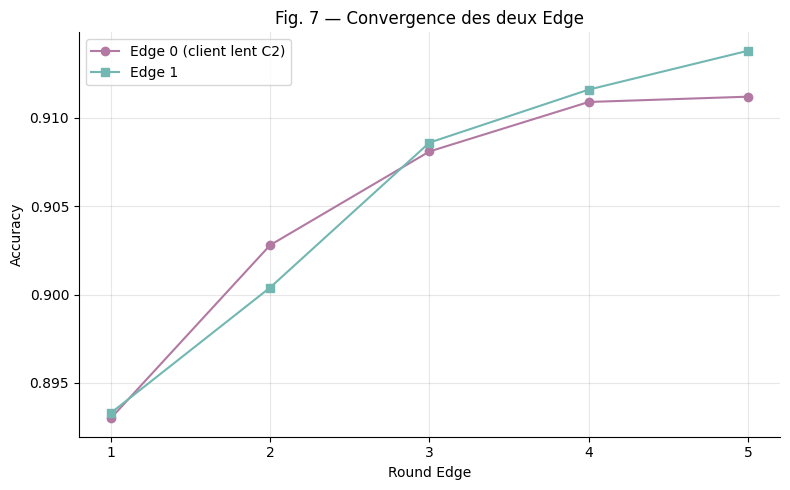

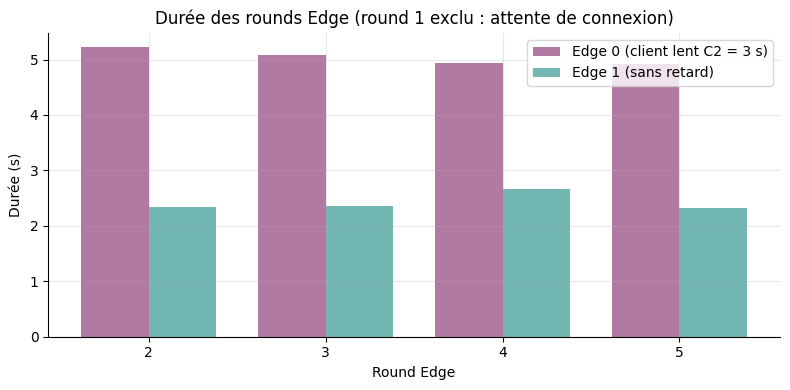

In [13]:
# Tableau 14 — observations des deux Edge (round 1 : durée de connexion exclue, voir section 0)
t14 = pd.DataFrame({'Round': edge0['round'],
                    'Accuracy Edge 0': edge0['accuracy'], 'Accuracy Edge 1': edge1['accuracy'],
                    'Durée Edge 0 (s)': edge0['round_duration_s'].where(edge0['round'] >= 2),
                    'Durée Edge 1 (s)': edge1['round_duration_s'].where(edge1['round'] >= 2)}).set_index('Round')
display(t14.round(4))
print('Durée moyenne (rounds 2–5) : Edge 0 =', round(e0_mean, 2), 's | Edge 1 =', round(e1_mean, 2), 's')

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(edge0['round'], edge0['accuracy'], marker='o', color=COL['E0'], label='Edge 0 (client lent C2)')
ax.plot(edge1['round'], edge1['accuracy'], marker='s', color=COL['E1'], label='Edge 1')
ax.set(xlabel='Round Edge', ylabel='Accuracy', title='Fig. 7 — Convergence des deux Edge')
ax.set_xticks(edge0['round']); ax.legend()
save('fig07_accuracy_edges')

fig, ax = plt.subplots(figsize=(8, 4))
w = .38
c0, c1 = clean(edge0), clean(edge1)
ax.bar(c0['round'] - w/2, c0['round_duration_s'], w, color=COL['E0'], label='Edge 0 (client lent C2 = 3 s)')
ax.bar(c1['round'] + w/2, c1['round_duration_s'], w, color=COL['E1'], label='Edge 1 (sans retard)')
ax.set(xlabel='Round Edge', ylabel='Durée (s)', title='Durée des rounds Edge (round 1 exclu : attente de connexion)')
ax.set_xticks(c0['round']); ax.legend()
save('extra_edge_durees')

### Tableau 15.2 — Agrégation Cloud uniforme vs pondérée

In [14]:
n_params = 784 * 10 + 10          # poids + biais du classifieur linéaire
taille_ko = n_params * 4 / 1024   # float32

t152 = {}
for sc in ['Équilibré', 'Déséquilibré']:
    for wgt, lab in [('uniform', 'Cloud uniforme'), ('examples', 'Cloud pondéré')]:
        r = cloud[(cloud['scenario'] == sc) & (cloud['weighting'] == wgt)].iloc[-1]
        t152[(sc, lab)] = {'Loss globale': r['loss'], 'Accuracy globale': r['accuracy'],
                           'Taille modèle global': f'{n_params} paramètres (≈ {taille_ko:.1f} Ko)'}
t152 = pd.DataFrame(t152)
display(t152)

# Poids de chaque Edge dans le cas déséquilibré (--max-train-samples 4000 / 1500, 3 clients par Edge)
N = {'Edge 0': 3 * 4000, 'Edge 1': 3 * 1500}
assert sum(N.values()) == cloud.loc[cloud['scenario'] == 'Déséquilibré', 'total_examples'].iloc[0]
print({k: f'{100*v/sum(N.values()):.1f} %' for k, v in N.items()}, '(pondéré) contre 50 % / 50 % (uniforme)')

Équilibré  \
                                   Cloud uniforme   
Loss globale                             0.311862   
Accuracy globale                            0.915   
Taille modèle global  7850 paramètres (≈ 30.7 Ko)   

                                                   \
                                    Cloud pondéré   
Loss globale                             0.311862   
Accuracy globale                            0.915   
Taille modèle global  7850 paramètres (≈ 30.7 Ko)   

                                     Déséquilibré                               
                                   Cloud uniforme                Cloud pondéré  
Loss globale                             0.399205                     0.380192  
Accuracy globale                           0.8944                       0.8984  
Taille modèle global  7850 paramètres (≈ 30.7 Ko)  7850 paramètres (≈ 30.7 Ko)

{'Edge 0': '72.7 %', 'Edge 1': '27.3 %'} (pondéré) contre 50 % / 50 % (uniforme)


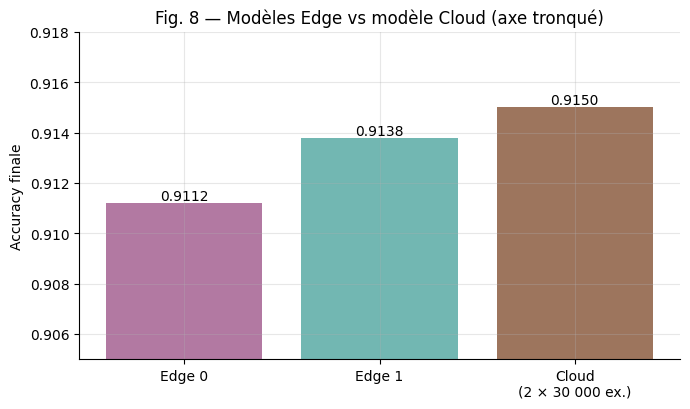

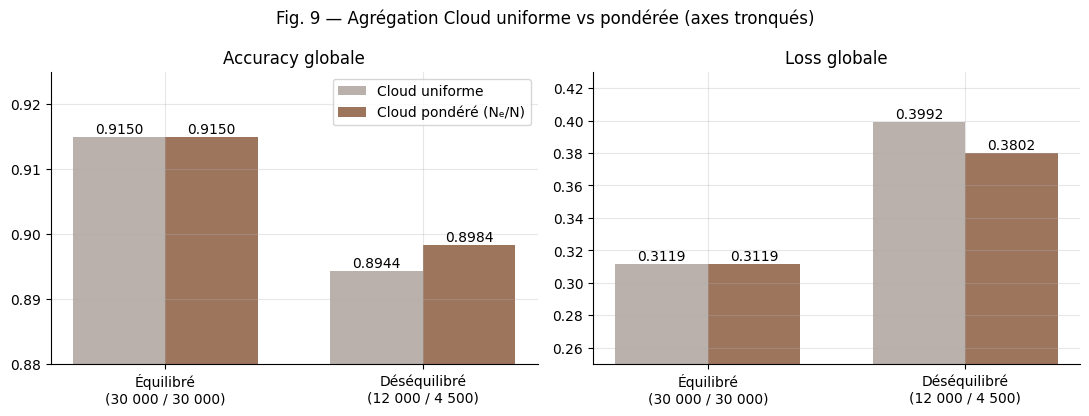

Déséquilibré : pondéré − uniforme = +0.40 pt d'accuracy, -0.0190 de loss (-4.8 %)
Équilibré : uniforme = pondéré ? True


In [15]:
def g(sc, wgt, col): return cloud[(cloud['scenario'] == sc) & (cloud['weighting'] == wgt)][col].iloc[-1]

# Fig. 8 — Edge vs Cloud (axe tronqué)
names = ['Edge 0', 'Edge 1', 'Cloud\n(2 × 30 000 ex.)']
accs = [edge0['accuracy'].iloc[-1], edge1['accuracy'].iloc[-1], g('Équilibré', 'uniform', 'accuracy')]
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(names, accs, color=[COL['E0'], COL['E1'], COL['Cloud']])
ax.bar_label(bars, fmt='%.4f'); ax.set_ylim(0.905, 0.918)
ax.set(ylabel='Accuracy finale', title='Fig. 8 — Modèles Edge vs modèle Cloud (axe tronqué)')
save('fig08_edge_vs_cloud')

# Fig. 9 — Cloud uniforme vs pondéré dans les deux configurations
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(2); w = .36
for ax, col, ttl in [(axes[0], 'accuracy', 'Accuracy globale'), (axes[1], 'loss', 'Loss globale')]:
    u = [g(sc, 'uniform', col) for sc in ['Équilibré', 'Déséquilibré']]
    p = [g(sc, 'examples', col) for sc in ['Équilibré', 'Déséquilibré']]
    b1 = ax.bar(x - w/2, u, w, label='Cloud uniforme', color='#BAB0AC')
    b2 = ax.bar(x + w/2, p, w, label='Cloud pondéré (Nₑ/N)', color=COL['Cloud'])
    ax.bar_label(b1, fmt='%.4f'); ax.bar_label(b2, fmt='%.4f')
    ax.set_xticks(x); ax.set_xticklabels(['Équilibré\n(30 000 / 30 000)', 'Déséquilibré\n(12 000 / 4 500)'])
    ax.set_title(ttl)
axes[0].set_ylim(0.88, 0.925); axes[1].set_ylim(0.25, 0.43); axes[0].legend(loc='upper right')
fig.suptitle('Fig. 9 — Agrégation Cloud uniforme vs pondérée (axes tronqués)')
save('fig09_cloud_uniforme_vs_pondere')

d_acc = 100 * (g('Déséquilibré', 'examples', 'accuracy') - g('Déséquilibré', 'uniform', 'accuracy'))
d_loss = g('Déséquilibré', 'examples', 'loss') - g('Déséquilibré', 'uniform', 'loss')
print(f'Déséquilibré : pondéré − uniforme = {d_acc:+.2f} pt d\'accuracy, {d_loss:+.4f} de loss '
      f'({100*d_loss/g("Déséquilibré","uniform","loss"):+.1f} %)')
print('Équilibré : uniforme = pondéré ?', np.isclose(g('Équilibré', 'uniform', 'loss'), g('Équilibré', 'examples', 'loss')))

## 5. Comparaison des architectures (Fig. 10 et tableaux 18 / 18.1)

,Accuracy finale,Loss finale,Temps total (s)
Expérience,,,
Sync homogène,0.9197,0.2909,21.0665
Sync hétérogène,0.9197,0.2909,33.5971
Async homogène,0.9152,0.3074,60.7142
Async hétérogène,0.9156,0.3075,78.7155
Edge–Cloud (client lent dans Edge 0),0.9150,0.3119,25.1934


Edge–Cloud : temps estimé = 5.04 s × 5 rounds (Edge le plus lent). Non strictement comparable : 6 clients × 10 000 ex. (Edge) contre 3 clients × 20 000 ex. (classique).


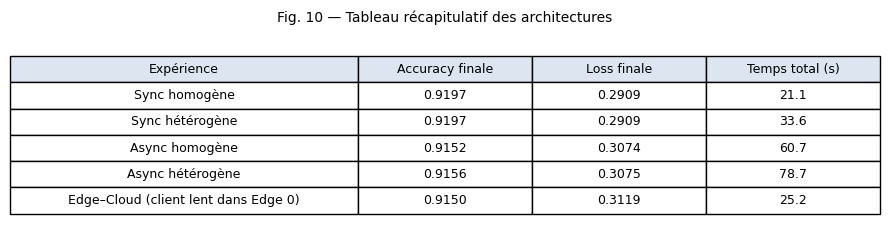

In [16]:
# Temps total Edge–Cloud : les deux Edge tournent en parallèle, le Cloud attend le plus lent.
# Le round 1 étant contaminé par l'attente de connexion, on l'estime par la moyenne des rounds 2–5.
n_rounds = len(edge0)
t_edge = max(e0_mean, e1_mean) * n_rounds
acc_c, loss_c = g('Équilibré', 'uniform', 'accuracy'), g('Équilibré', 'uniform', 'loss')

t181 = pd.DataFrame([
    ['Sync homogène',   sync_h['accuracy'].iloc[-1],  sync_h['loss'].iloc[-1],  tot_s1],
    ['Sync hétérogène', sync_s['accuracy'].iloc[-1],  sync_s['loss'].iloc[-1],  tot_s2],
    ['Async homogène',  async_h['accuracy'].iloc[-1], async_h['loss'].iloc[-1], tot_a1],
    ['Async hétérogène', async_s['accuracy'].iloc[-1], async_s['loss'].iloc[-1], tot_a2],
    ['Edge–Cloud (client lent dans Edge 0)', acc_c, loss_c, t_edge],
], columns=['Expérience', 'Accuracy finale', 'Loss finale', 'Temps total (s)']).set_index('Expérience')
display(t181.round(4))
t181.round(4).to_csv(FIG / 'tableau_resultats.csv')
print(f"Edge–Cloud : temps estimé = {e0_mean:.2f} s × {n_rounds} rounds (Edge le plus lent). "
      "Non strictement comparable : 6 clients × 10 000 ex. (Edge) contre 3 clients × 20 000 ex. (classique).")

# Fig. 10 — tableau final rendu en image
fig, ax = plt.subplots(figsize=(9, 2.6)); ax.axis('off')
cell = [[i, f'{r["Accuracy finale"]:.4f}', f'{r["Loss finale"]:.4f}', f'{r["Temps total (s)"]:.1f}']
        for i, r in t181.iterrows()]
tb = ax.table(cellText=cell, colLabels=['Expérience', 'Accuracy finale', 'Loss finale', 'Temps total (s)'],
              loc='center', cellLoc='center', colWidths=[.4, .2, .2, .2])
tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1, 1.5)
for j in range(4): tb[0, j].set_facecolor('#DDE6F0')
ax.set_title('Fig. 10 — Tableau récapitulatif des architectures', fontsize=10)
save('fig10_tableau_final')

### Tableau 18 — Comparaison qualitative des architectures (chaque case s'appuie sur une mesure)

In [17]:
dec_e = int((edge0['accuracy'].diff() < 0).sum() + (edge1['accuracy'].diff() < 0).sum())
t18 = pd.DataFrame({
 'Classique synchrone': [
   '1 (serveur ↔ clients)',
   f"{sync_s['accuracy'].iloc[-1]:.4f} après 5 rounds, croissante",
   f"{dec_s} baisse d'accuracy sur 4",
   f"Forte : +{100*(sync_s['round_duration_s'].mean()/sync_h['round_duration_s'].mean()-1):.0f} % de durée par round, pour tout le système",
   '3 mises à jour reçues par round (15 au total)',
   'Aucune : FedAvg direct à chaque round',
   'Faible',
   'Faible à moyenne (barrière de synchronisation)'],
 'Classique asynchrone': [
   '1 (serveur ↔ clients)',
   f"{async_s['accuracy'].iloc[-1]:.4f} après 15 mises à jour",
   f"{dec_a} baisses d'accuracy sur 14 ; staleness = 2",
   f"+{100*(tot_a2/tot_a1-1):.0f} % de temps total ; contributions inchangées (5/5/5) dans ce banc d'essai",
   '15 mises à jour traitées une à une, avec 15 évaluations',
   'À chaque mise à jour (mélange α = 1/3)',
   'Moyenne à élevée (concurrence, staleness)',
   'Moyenne : tolère les clients lents, mais irrégulière'],
 'Edge–Cloud': [
   '2 (clients → Edge → Cloud)',
   f"{acc_c:.4f} (Cloud) ; Edge : {edge0['accuracy'].iloc[-1]:.4f} / {edge1['accuracy'].iloc[-1]:.4f}",
   f"{dec_e} baisse d'accuracy dans les Edge (croissance régulière)",
   f"Localisée : Edge 0 ×{e0_mean/e1_mean:.2f} ({e0_mean:.2f} s), Edge 1 inchangé ({e1_mean:.2f} s)",
   '2 modèles agrégés une fois (≈ 31 Ko chacun) ; 6 clients non connectés au Cloud',
   '5 agrégations par Edge (10 au total) puis 1 agrégation Cloud',
   'Élevée (2 niveaux, fichiers de paramètres, pondération)',
   'Élevée : passage à l\'échelle, regroupement géographique, charge centrale réduite'],
}, index=['Nombre de niveaux', 'Convergence', 'Stabilité', 'Sensibilité aux clients lents',
          'Charge du serveur central', 'Agrégations intermédiaires', 'Complexité', 'Pertinence IoT'])
display(t18)

,Classique synchrone,Classique asynchrone,Edge–Cloud
Nombre de niveaux,1 (serveur ↔ clients),1 (serveur ↔ clients),2 (clients → Edge → Cloud)
Convergence,"0.9197 après 5 rounds, croissante",0.9156 après 15 mises à jour,0.9150 (Cloud) ; Edge : 0.9112 / 0.9138
Stabilité,0 baisse d'accuracy sur 4,5 baisses d'accuracy sur 14 ; staleness = 2,0 baisse d'accuracy dans les Edge (croissance régulière)
Sensibilité aux clients lents,"Forte : +59 % de durée par round, pour tout le système",+30 % de temps total ; contributions inchangées (5/5/5) dans ce banc d'essai,"Localisée : Edge 0 ×2.08 (5.04 s), Edge 1 inchangé (2.42 s)"
Charge du serveur central,3 mises à jour reçues par round (15 au total),"15 mises à jour traitées une à une, avec 15 évaluations",2 modèles agrégés une fois (≈ 31 Ko chacun) ; 6 clients non connectés au Cloud
Agrégations intermédiaires,Aucune : FedAvg direct à chaque round,À chaque mise à jour (mélange α = 1/3),5 agrégations par Edge (10 au total) puis 1 agrégation Cloud
Complexité,Faible,"Moyenne à élevée (concurrence, staleness)","Élevée (2 niveaux, fichiers de paramètres, pondération)"
Pertinence IoT,Faible à moyenne (barrière de synchronisation),"Moyenne : tolère les clients lents, mais irrégulière","Élevée : passage à l'échelle, regroupement géographique, charge centrale réduite"


## 6. Analyse rédigée

*Conditions de mesure : une seule exécution par scénario, sur une seule machine dont le CPU est partagé par le serveur et tous les clients, retards simulés par `time.sleep`. Les écarts inférieurs à 0,5 point d'accuracy sont à lire avec prudence (pas de répétitions, donc pas d'écart-type).*

**1. Effet d'un straggler sur la durée des rounds synchrones.**
La durée moyenne d'un round passe de **4,21 s (S1) à 6,72 s (S2)**, soit +2,51 s (+59,5 %) ; le temps total passe de 21,07 s à 33,60 s. C'est cohérent avec `T_round ≈ max(Tₖ)` : le client à 3 s fixe la cadence et les deux autres attendent. L'accuracy finale (0,9197) et la loss finale (0,2909) sont identiques : le retard coûte du temps, pas de qualité.

**2. Répartition des contributions en asynchrone.**
Contrairement à l'attendu, **les clients rapides n'ont pas contribué davantage** : 5 / 5 / 5 dans A1 comme dans A2. L'ordre d'arrivée est un tourniquet strict (0, 2, 1, 0, 2, 1…) et la staleness vaut 0, 1 puis reste constante à 2 (= N − 1) pour 13 mises à jour sur 15. Hypothèse (non testée) : les trois processus se partagent le même CPU et l'entraînement local (≈ 3,5 s par mise à jour traitée) domine les retards de 1 s et 3 s ; chaque client attend surtout son tour, ce qui masque l'essentiel du retard. Le retard reste toutefois visible : l'écart entre arrivées est de 7,0 à 8,3 s avant chaque mise à jour du client lent, contre 3,2 à 4,9 s pour les autres, et le temps total augmente de 18,0 s (+30 %). Pour observer l'avantage théorique de l'asynchrone, il faudrait des retards très supérieurs au temps de calcul (p. ex. 10 à 20 s).

**3. Stabilité de la convergence synchrone / asynchrone.**
En synchrone, l'accuracy augmente à chaque round (0 baisse sur 4) et la loss diminue régulièrement. En asynchrone, la loss diminue à chaque mise à jour, mais l'accuracy baisse 3 fois sur 14 (A1) et 5 fois sur 14 (A2) (écart-type de Δaccuracy 0,0030 et 0,0046) : chaque mise à jour tire le modèle de 1/3 vers un seul client, calculé sur un modèle déjà dépassé. À budget égal (15 contributions), le synchrone atteint 0,9197 / 0,2909 contre 0,9156 / 0,3075 pour A2, et il est plus rapide (33,6 s contre 78,7 s ; ×2,3, et ×2,9 sans retard). Dans ce banc d'essai l'asynchrone n'est donc **ni plus rapide ni plus précis** : le serveur pédagogique traite les mises à jour une par une, évalue à chacune, et la machine unique limite le parallélisme réel. Ce résultat est propre à ce montage et ne se généralise pas tel quel.

**4. Différences Edge 0 / Edge 1.**
Round 1 exclu (≈ 470 s de connexion, voir section 0), Edge 0 (client lent C2 = 3 s) dure **5,04 s par round** contre **2,42 s** pour Edge 1 (×2,08). Edge 1 n'est pas ralenti : le retard provient de la synchronisation locale d'Edge 0, pas de l'étape Cloud. Les accuracy finales sont proches (0,9112 contre 0,9138) et les loss aussi (0,3143 contre 0,3155) : les données étant IID, ces écarts sont du même ordre que le bruit d'initialisation et de partitionnement.

**5. Effet de la pondération Cloud.**
Avec deux Edge de même taille (30 000 / 30 000 exemples), uniforme et pondéré donnent exactement le même modèle (0,9150 ; loss 0,3119), puisque les poids sont identiques (50 / 50). Avec des Edge déséquilibrés (12 000 / 4 500 exemples, poids pondérés 72,7 % / 27,3 %), la version pondérée est meilleure : **0,8984 contre 0,8944** d'accuracy (+0,40 pt) et **0,3802 contre 0,3992** de loss (−0,019, soit −4,8 %). L'accuracy absolue est plus basse dans ce cas parce que le système n'utilise que 16 500 exemples au lieu de 60 000. Dans le cas équilibré, le modèle Cloud (0,9150) dépasse les deux Edge (0,9112 et 0,9138) : l'agrégation globale apporte un gain.

**6. Recommandation pour un environnement IoT hétérogène.**
Nous recommandons une **architecture hiérarchique Edge–Cloud, avec FedAvg synchrone dans chaque Edge et agrégation Cloud pondérée par le nombre d'exemples**, pour quatre raisons tirées de nos mesures :
1. *Isolation des retards.* Un client à 3 s multiplie par 2,08 la durée des rounds de son Edge (5,04 s) mais laisse Edge 1 inchangé (2,42 s) ; en synchrone classique le même client ralentit tout le système (+59,5 % par round).
2. *Charge centrale réduite.* Le Cloud agrège une seule fois 2 modèles de 7 850 paramètres (≈ 31 Ko), au lieu de recevoir 3 mises à jour par round ou 15 mises à jour traitées une à une ; les appareils ne communiquent qu'avec leur Edge.
3. *Coût de qualité faible et convergence régulière.* 0,9150 contre 0,9197 en synchrone (−0,47 pt) et 0,9156 en asynchrone, avec 0 baisse d'accuracy dans les Edge contre 5 sur 14 en asynchrone.
4. *Pondération indispensable si les groupes sont inégaux* : +0,40 pt d'accuracy et −0,019 de loss par rapport à la moyenne uniforme.

*Limites.* À l'intérieur d'un Edge synchrone, un client lent ralentit encore son groupe : prévoir un délai maximal ou une participation partielle (hors périmètre du TP). Le temps Edge–Cloud estimé (≈ 25 s contre 33,6 s) n'est pas strictement comparable au classique (6 clients de 10 000 exemples contre 3 de 20 000). L'asynchrone n'a pas montré d'avantage ici ; il mériterait d'être retesté avec des retards bien supérieurs au temps de calcul.

## 7. Réponses courtes aux questions d'analyse

1. **Rôle de Flower** : il gère la communication client/serveur, l'orchestration des rounds, la distribution du modèle et la stratégie d'agrégation (FedAvg) ; l'entraînement est fait par PyTorch.
2. **Entraînement local vs agrégation** : le premier a lieu chez le client sur ses données (`fit`) ; la seconde combine, côté serveur, les paramètres reçus.
3. **Synchrone et clients lents** : le serveur attend tous les clients sélectionnés avant d'agréger, donc `T_round ≈ max(Tₖ)` (Fig. 3 et 6).
4. **Ce que change l'asynchronisme** : chaque mise à jour est appliquée à son arrivée, sans barrière, mais sur un modèle qui a pu changer entre-temps.
5. **Irrégularité de l'asynchrone** : la staleness (ici 2) fait agréger des mises à jour calculées sur un modèle dépassé ; l'accuracy baisse 5 fois sur 14 en A2, jamais en synchrone.
6. **Rôle d'un Edge** : agréger localement un groupe de clients proches (FedAvg Flower), sauvegarder le modèle intermédiaire et alléger le Cloud.
7. **Agrégation Edge vs Cloud** : l'Edge agrège à chaque round, avec Flower, les mises à jour de ses clients ; le Cloud combine une seule fois les modèles Edge (fichiers `.npz`), de façon uniforme ou pondérée.
8. **Pertinence pour l'IoT** : appareils nombreux et regroupés, retards isolés par groupe, moins de trafic vers le Cloud et charge centrale réduite.
9. **Poids de deux Edge de tailles différentes** : non, un Edge qui représente plus d'exemples doit peser davantage (Nₑ/N) ; mesuré : +0,40 pt et −0,019 de loss.
10. **Le Cloud est-il entraîné sur MNIST ?** Non : il moyenne des paramètres déjà entraînés ; MNIST ne sert qu'à l'évaluer sur le jeu de test global.
11. **Les données locales vont-elles au Cloud ?** Non : seuls les paramètres (7 850 valeurs) et des métadonnées (nombre d'exemples) circulent.
12. **Architecture pour de nombreux clients regroupés** : Edge–Cloud avec Cloud pondéré (voir recommandation, section 6).